In [ ]:
import json
import math
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

In [6]:
FILE_RE = re.compile(r"^(\d+(?:\.\d+)*)_results\.json$")


def version_key(v: str):
    return tuple(int(p) for p in v.split("."))


def normalize_backend(backend: str) -> str:
    # "PyTorch 2.13.0+cu130 (CPU, 6 threads)" -> "PyTorch (CPU, 6 threads)"
    # so the same series is tracked across torch upgrades.
    return re.sub(r"(PyTorch)\s+\S+", r"\1", backend)


def load(folder: Path):
    """Return {model: {(runner, backend): {version: entry}}} and sorted versions."""
    data = defaultdict(lambda: defaultdict(dict))
    versions = []
    for path in folder.glob("*_results.json"):
        m = FILE_RE.match(path.name)
        if not m:
            continue
        version = m.group(1)
        versions.append(version)
        with open(path) as f:
            doc = json.load(f)
        for model_block in doc["results"]:
            model = model_block["model"]
            for r in model_block["results"]:
                key = (r["runner"], normalize_backend(r["backend"]))
                data[model][key][version] = r
    versions.sort(key=version_key)
    return data, versions

In [ ]:
# One fixed style per backend, identical in every panel. PyTorch is the reference,
# so it is drawn as a neutral dashed baseline; the Rust backends get distinct
# colors (colorblind-safe set) plus distinct markers.
STYLES = {
    "PyTorch": dict(color="#3d3d3a", marker="s", linestyle="--"),
    "ndarray (matrixmultiply)": dict(color="#2a78d6", marker="o", linestyle="-"),
    "simd (wide)": dict(color="#eb6834", marker="^", linestyle="-"),
    "ndarray (BLAS)": dict(color="#1baf7a", marker="D", linestyle="-"),
}
FALLBACK_STYLE = dict(color="#8a8a85", marker="x", linestyle=":")


def split_runner(runner: str) -> str:
    # "rust@pi4" -> "pi4", "rust" -> "local"
    return runner.split("@", 1)[1] if "@" in runner else "local"


def backend_label(backend: str) -> str:
    # "PyTorch (CPU, 6 threads)" -> "PyTorch": thread counts differ per device.
    return "PyTorch" if backend.startswith("PyTorch") else backend


def fmt_time(ns: float, _pos=None) -> str:
    for unit, scale in (("s", 1e9), ("ms", 1e6), ("µs", 1e3)):
        if ns >= scale:
            v = ns / scale
            return f"{v:.3g} {unit}"
    return f"{ns:.3g} ns"


def regroup(data):
    """{model: {(runner, backend): {version: entry}}} -> {model: {device: {backend: {version: entry}}}}."""
    out = defaultdict(lambda: defaultdict(dict))
    for model, series in data.items():
        for (runner, backend), per_version in series.items():
            out[model][split_runner(runner)][backend_label(backend)] = per_version
    return out


def backend_order(name: str):
    keys = list(STYLES)
    return (keys.index(name) if name in keys else len(keys), name)

In [ ]:
folder = "."
metric = "median_ns"  # choices=["median_ns", "mean_ns", "min_ns", "max_ns"]
log_scale = True  # timings span several orders of magnitude; linear hides the fast series
show_spread = False  # shade median ± std dev (clipped to min/max); noisy BLAS runs make this busy
share_y_per_model = True  # same y range for every device of a model, so devices are comparable

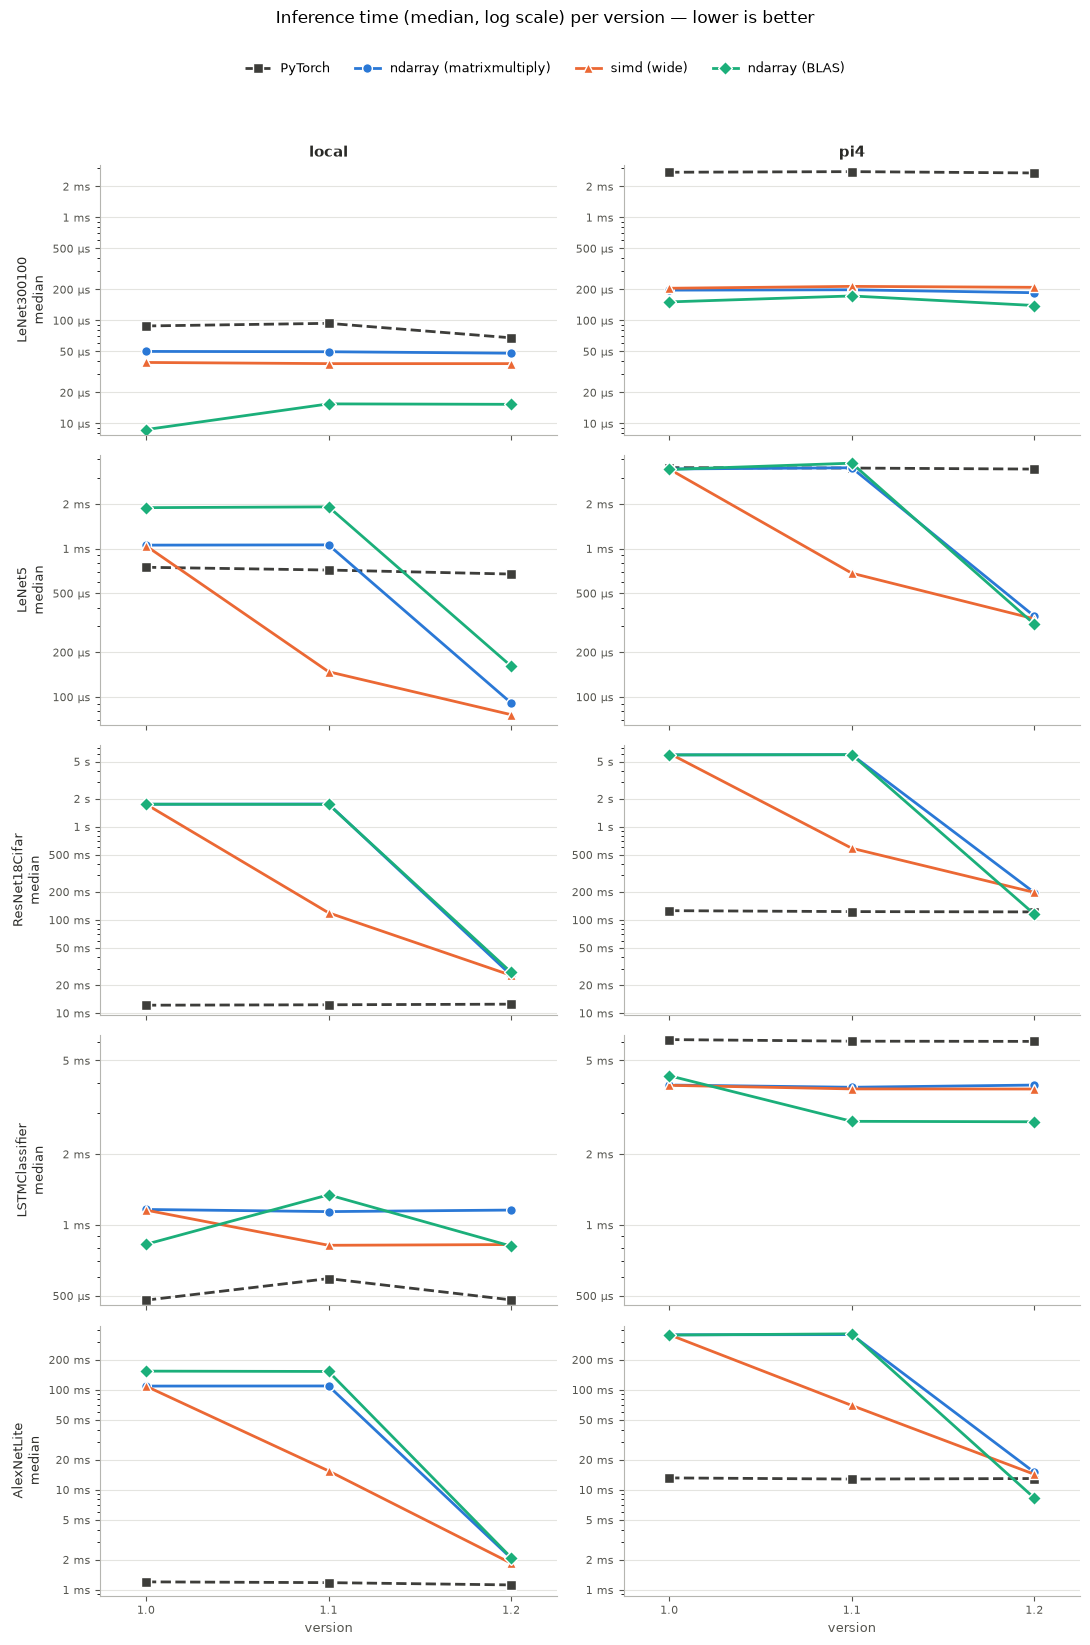

In [ ]:
data, versions = load(Path(folder))
if not versions:
    raise SystemExit(f"No '<version>_results.json' files found in {folder}")

grouped = regroup(data)
models = list(grouped)
devices = sorted({d for m in grouped.values() for d in m}, key=lambda d: (d != "local", d))
x_pos = {v: i for i, v in enumerate(versions)}  # categorical x: evenly spaced
metric_name = metric.replace("_ns", "")

fig, axes = plt.subplots(
    len(models),
    len(devices),
    figsize=(5.5 * len(devices), 3.2 * len(models)),
    squeeze=False,
    sharex=True,
)

for row, model in enumerate(models):
    for col, device in enumerate(devices):
        ax = axes[row][col]
        series = grouped[model].get(device, {})
        for backend in sorted(series, key=backend_order):
            per_version = series[backend]
            style = STYLES.get(backend, FALLBACK_STYLE)
            vs = [v for v in versions if v in per_version]
            xs = [x_pos[v] for v in vs]
            ys = [per_version[v][metric] for v in vs]
            ax.plot(xs, ys, linewidth=2, markersize=7, markeredgecolor="white", markeredgewidth=1, label=backend, **style)
            if show_spread:
                lo = [max(per_version[v][metric] - per_version[v]["std_dev_ns"], per_version[v]["min_ns"]) for v in vs]
                hi = [min(per_version[v][metric] + per_version[v]["std_dev_ns"], per_version[v]["max_ns"]) for v in vs]
                ax.fill_between(xs, lo, hi, color=style["color"], alpha=0.12, linewidth=0)

        if log_scale:
            ax.set_yscale("log")
            ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
            ax.yaxis.set_minor_formatter(NullFormatter())
        ax.yaxis.set_major_formatter(FuncFormatter(fmt_time))
        ax.grid(True, which="major", axis="y", color="#e4e4e0", linewidth=0.8)
        ax.grid(False, axis="x")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b5b0")
        ax.tick_params(colors="#55554f", labelsize=8)
        ax.set_xticks(range(len(versions)))
        ax.set_xticklabels(versions)
        ax.set_xlim(-0.25, len(versions) - 0.75)

        if row == 0:
            ax.set_title(device, fontsize=11, fontweight="bold", color="#2a2a27")
        if col == 0:
            ax.set_ylabel(f"{model}\n{metric_name}", fontsize=9, color="#2a2a27")
        if row == len(models) - 1:
            ax.set_xlabel("version", fontsize=9, color="#55554f")

    if share_y_per_model:
        row_axes = axes[row]
        lo = min(a.get_ylim()[0] for a in row_axes)
        hi = max(a.get_ylim()[1] for a in row_axes)
        for a in row_axes:
            a.set_ylim(lo, hi)

legend_backends = sorted({b for m in grouped.values() for d in m.values() for b in d}, key=backend_order)
handles = [Line2D([], [], linewidth=2, markersize=7, markeredgecolor="white", label=b, **STYLES.get(b, FALLBACK_STYLE)) for b in legend_backends]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=9)
scale_note = "log scale" if log_scale else "linear scale"
spread_note = ", band = ±1 std dev" if show_spread else ""
fig.suptitle(f"Inference time ({metric_name}, {scale_note}{spread_note}) per version — lower is better", y=1.025, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## Speedup vs PyTorch (latest version)

Each Rust backend's time relative to PyTorch on the same device. Bars to the right of the 1× line are faster than PyTorch.


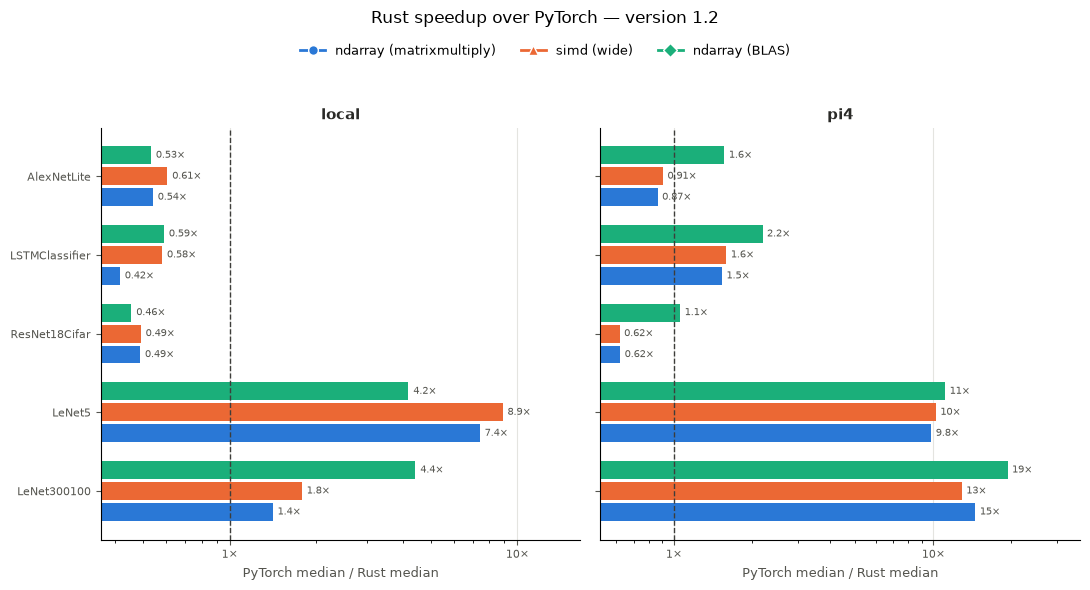

In [ ]:
latest = versions[-1]
rust_backends = [b for b in legend_backends if b != "PyTorch"]
bar_h = 0.8 / max(len(rust_backends), 1)

fig, axes = plt.subplots(1, len(devices), figsize=(5.5 * len(devices), 0.55 * len(models) * len(rust_backends) / 2 + 1.5), squeeze=False, sharey=True)
for ax, device in zip(axes[0], devices):
    for i, backend in enumerate(rust_backends):
        ys, ratios = [], []
        for j, model in enumerate(models):
            series = grouped[model].get(device, {})
            ref = series.get("PyTorch", {}).get(latest)
            cur = series.get(backend, {}).get(latest)
            if ref and cur:
                ys.append(j + (i - (len(rust_backends) - 1) / 2) * bar_h)
                ratios.append(ref[metric] / cur[metric])
        style = STYLES.get(backend, FALLBACK_STYLE)
        bars = ax.barh(ys, ratios, height=bar_h * 0.85, color=style["color"], label=backend)
        for y, r in zip(ys, ratios):
            ax.text(r * 1.04, y, f"{r:.2g}×", va="center", fontsize=7, color="#55554f")
    ax.axvline(1, color="#3d3d3a", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _p: f"{v:g}×"))
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels(models, fontsize=9)
    ax.invert_yaxis()
    ax.set_title(device, fontsize=11, fontweight="bold", color="#2a2a27")
    ax.set_xlabel(f"PyTorch {metric_name} / Rust {metric_name}", fontsize=9, color="#55554f")
    ax.grid(True, axis="x", which="major", color="#e4e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors="#55554f", labelsize=8)
    lo, hi = ax.get_xlim()
    ax.set_xlim(lo, hi * 1.6)  # room for the value labels

fig.legend(
    handles=[h for h in handles if h.get_label() != "PyTorch"],
    loc="upper center",
    ncol=len(rust_backends),
    frameon=False,
    bbox_to_anchor=(0.5, 1.0),
    fontsize=9,
)
fig.suptitle(f"Rust speedup over PyTorch — version {latest}", y=1.04, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()